# Laboratorium 1 – sieć samoorganizująca SOM (część pierwsza)

## 1. Przygotowanie środowiska

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

np.random.seed(42)

## 2. Wczytanie danych

In [52]:
iris = load_iris()

X = iris.data      
y = iris.target    

nazwy_cech = iris.feature_names
nazwy_klas = list(iris.target_names)

print("Cechy:", nazwy_cech)
print("Klasy:", nazwy_klas)

Cechy: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Klasy: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## 3. Analiza danych

In [47]:
print("Liczba wierszy (przykładów):", X.shape[0])
print("Liczba cech:", X.shape[1])
print("Liczba klas:", len(nazwy_klas))

Liczba wierszy (przykładów): 150
Liczba cech: 4
Liczba klas: 3


In [48]:
for numer in range(3):
    ile = np.sum(y == numer)
    print(nazwy_klas[numer], ":", ile)

setosa : 50
versicolor : 50
virginica : 50


In [30]:
df = pd.DataFrame(X, columns=nazwy_cech)
df["gatunek"] = [nazwy_klas[i] for i in y]
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),gatunek
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [31]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [32]:
df.groupby("gatunek").mean()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
gatunek,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


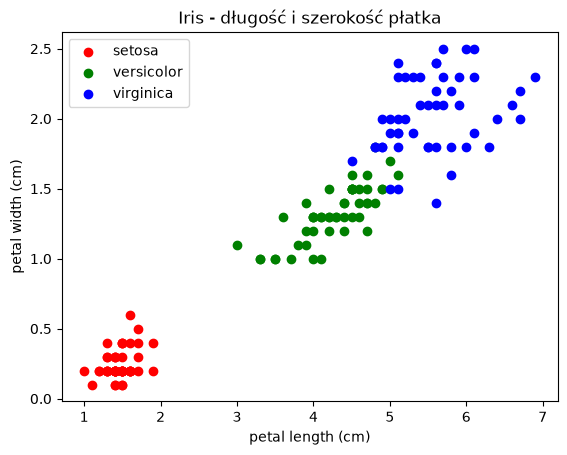

In [33]:
kolory = ["red", "green", "blue"]
for numer in range(3):
    plt.scatter(X[y == numer, 2], X[y == numer, 3],
                color=kolory[numer], label=nazwy_klas[numer])
plt.xlabel(nazwy_cech[2])
plt.ylabel(nazwy_cech[3])
plt.title("Iris - długość i szerokość płatka")
plt.legend()
plt.show()

Na wykresie widać, że **setosa** jest wyraźnie oddzielona od reszty, a **versicolor** i **virginica** trochę się nakładają.
Sieć SOM nie zna gatunków, więc można się spodziewać, że setosę rozpozna łatwo, a pozostałe dwie czasem pomiesza.

## 4. Normalizacja (bez gotowej funkcji)

In [53]:
X_norm = np.zeros(X.shape)

for kolumna in range(4):
    minimum = X[:, kolumna].min()
    maksimum = X[:, kolumna].max()
    X_norm[:, kolumna] = (X[:, kolumna] - minimum) / (maksimum - minimum)

print("Minimum każdej cechy po normalizacji:", X_norm.min(axis=0))
print("Maksimum każdej cechy po normalizacji:", X_norm.max(axis=0))

Minimum każdej cechy po normalizacji: [0. 0. 0. 0.]
Maksimum każdej cechy po normalizacji: [1. 1. 1. 1.]


In [35]:
print("Przed:")
print(X[:3])
print("Po:")
print(X_norm[:3].round(3))

Przed:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]]
Po:
[[0.222 0.625 0.068 0.042]
 [0.167 0.417 0.068 0.042]
 [0.111 0.5   0.051 0.042]]


## 5. Utworzenie neuronów

In [49]:
liczba_neuronow = 3
liczba_wejsc = 4

wagi = np.random.rand(liczba_neuronow, liczba_wejsc)

print("Początkowe wagi neuronów:")
print(wagi.round(3))

Początkowe wagi neuronów:
[[0.832 0.212 0.182 0.183]
 [0.304 0.525 0.432 0.291]
 [0.612 0.139 0.292 0.366]]


## 6. Odległość

In [37]:
def odleglosc(x, w):
    suma = 0
    for i in range(len(x)):
        suma = suma + (x[i] - w[i]) ** 2
    return suma ** 0.5

In [38]:
przyklad = X_norm[0]
for n in range(3):
    print("Odległość przykładu 0 od neuronu", n, ":", round(odleglosc(przyklad, wagi[n]), 4))

Odległość przykładu 0 od neuronu 0 : 0.9385
Odległość przykładu 0 od neuronu 1 : 0.9509
Odległość przykładu 0 od neuronu 2 : 1.0071


## 7. Neuron zwycięski

Zwycięzca to neuron o **najmniejszej** odległości od przykładu.

In [39]:
def znajdz_zwyciezce(x, wagi):
    najlepszy = 0
    najmniejsza = odleglosc(x, wagi[0])

    for n in range(1, len(wagi)):
        d = odleglosc(x, wagi[n])
        if d < najmniejsza:
            najmniejsza = d
            najlepszy = n

    return najlepszy

In [40]:
zwyciezca = znajdz_zwyciezce(X_norm[0], wagi)
print("Dla przykładu 0 wygrywa neuron:", zwyciezca)

Dla przykładu 0 wygrywa neuron: 0


## 8. Aktualizacja wag

In [41]:
def aktualizuj_wagi(x, wagi, numer_zwyciezcy, alfa):
    for i in range(len(x)):
        wagi[numer_zwyciezcy][i] = wagi[numer_zwyciezcy][i] + alfa * (x[i] - wagi[numer_zwyciezcy][i])

In [50]:
alfa = 0.5
przyklad = X_norm[0]
zwyciezca = znajdz_zwyciezce(przyklad, wagi)

print("Przykład:                ", przyklad.round(3))
print("Wagi zwycięzcy PRZED:    ", wagi[zwyciezca].round(3))

aktualizuj_wagi(przyklad, wagi, zwyciezca, alfa)

print("Wagi zwycięzcy PO:       ", wagi[zwyciezca].round(3))
print("Odległość po aktualizacji:", round(odleglosc(przyklad, wagi[zwyciezca]), 4))

Przykład:                 [0.222 0.625 0.068 0.042]
Wagi zwycięzcy PRZED:     [0.304 0.525 0.432 0.291]
Wagi zwycięzcy PO:        [0.263 0.575 0.25  0.166]
Odległość po aktualizacji: 0.23


In [43]:
for i in range(10):
    x = X_norm[i]
    z = znajdz_zwyciezce(x, wagi)
    aktualizuj_wagi(x, wagi, z, 0.1)

print("Wagi po 10 przykładach:")
print(wagi.round(3))

Wagi po 10 przykładach:
[[0.202 0.626 0.19  0.143]
 [0.156 0.156 0.058 0.866]
 [0.601 0.708 0.021 0.97 ]]
